In [1]:
import pandas as pd

In [47]:
df= pd.read_excel('R:\Projects\Electricity Demand Prediction\Code\DailyPredictionModel\DD.xlsx')

In [48]:
df.tail()

,Date,Weekday,Temperature,Humidity,Wind_speed,is_Holiday,Conditions,Daily Demand Met (in MW),Season
3567,2024-11-16,Saturday,22.3,62.9,9.4,0,True,3663,Autumn
3568,2024-11-17,Sunday,20.3,73.0,16.6,0,False,3604,Autumn
3569,2024-11-18,Monday,21.1,59.0,11.2,0,False,3774,Autumn
3570,2024-11-19,Tuesday,23.3,21.7,10.4,0,True,3880,Autumn
3571,2024-11-20,Wednesday,23.1,19.2,10.4,0,True,3890,Autumn


In [49]:
df.isnull().sum()

Date                        0
Weekday                     0
Temperature                 0
Humidity                    0
Wind_speed                  0
is_Holiday                  0
Conditions                  0
Daily Demand Met (in MW)    0
Season                      0
dtype: int64

In [50]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3572 entries, 0 to 3571
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Date                      3572 non-null   datetime64[ns]
 1   Weekday                   3572 non-null   object        
 2   Temperature               3572 non-null   float64       
 3   Humidity                  3572 non-null   float64       
 4   Wind_speed                3572 non-null   float64       
 5   is_Holiday                3572 non-null   int64         
 6   Conditions                3572 non-null   object        
 7   Daily Demand Met (in MW)  3572 non-null   int64         
 8   Season                    3572 non-null   object        
dtypes: datetime64[ns](1), float64(3), int64(2), object(3)
memory usage: 251.3+ KB


In [51]:
print(df.isna().sum())

Date                        0
Weekday                     0
Temperature                 0
Humidity                    0
Wind_speed                  0
is_Holiday                  0
Conditions                  0
Daily Demand Met (in MW)    0
Season                      0
dtype: int64


In [52]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3572 entries, 0 to 3571
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Date                      3572 non-null   datetime64[ns]
 1   Weekday                   3572 non-null   object        
 2   Temperature               3572 non-null   float64       
 3   Humidity                  3572 non-null   float64       
 4   Wind_speed                3572 non-null   float64       
 5   is_Holiday                3572 non-null   int64         
 6   Conditions                3572 non-null   object        
 7   Daily Demand Met (in MW)  3572 non-null   int64         
 8   Season                    3572 non-null   object        
dtypes: datetime64[ns](1), float64(3), int64(2), object(3)
memory usage: 251.3+ KB


In [53]:
# Convert 'WeekDay' to categorical data using LabelEncoder
from sklearn.preprocessing import LabelEncoder, StandardScaler
import seaborn as sns
import matplotlib.pyplot as plt
le = LabelEncoder()
df['Weekday'] = le.fit_transform(df['Weekday'])

In [54]:
df.tail()

,Date,Weekday,Temperature,Humidity,Wind_speed,is_Holiday,Conditions,Daily Demand Met (in MW),Season
3567,2024-11-16,2,22.3,62.9,9.4,0,True,3663,Autumn
3568,2024-11-17,3,20.3,73.0,16.6,0,False,3604,Autumn
3569,2024-11-18,1,21.1,59.0,11.2,0,False,3774,Autumn
3570,2024-11-19,5,23.3,21.7,10.4,0,True,3880,Autumn
3571,2024-11-20,6,23.1,19.2,10.4,0,True,3890,Autumn


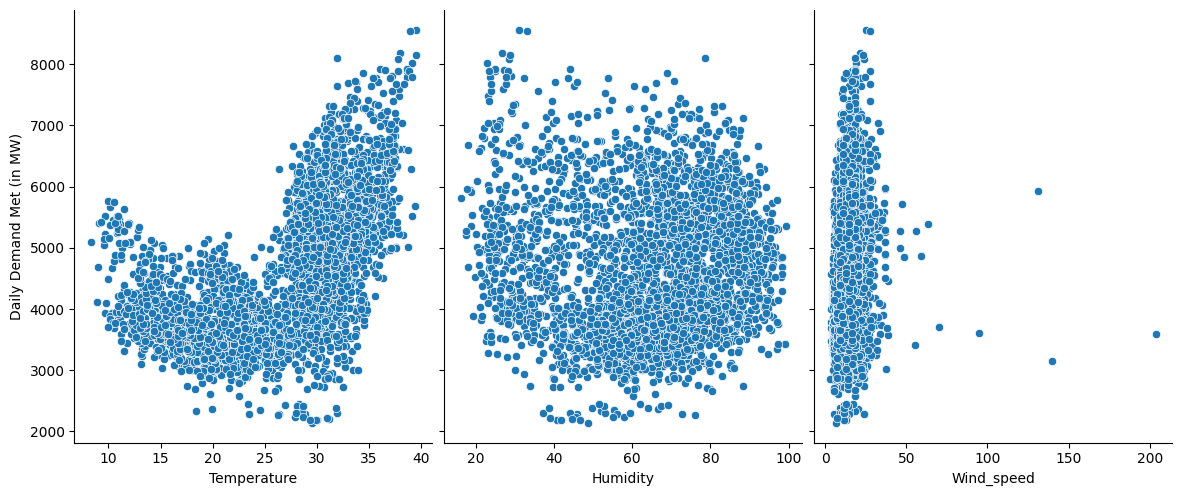

In [55]:
season_mapping = {
    'Light Winter': 0,
    'Heavy Winter': 1,
    'Light Summer': 2,
    'Heavy Summer': 3,
    'Light Rainy':4,
    'Rainy': 5,
    'Autumn': 6
}

df['Season'] = df['Season'].map(season_mapping)
# Pairplot for visualizing relationships
sns.pairplot(df, x_vars=['Temperature', 'Humidity', 'Wind_speed'], y_vars='Daily Demand Met (in MW)', height=5, aspect=0.8)
plt.show()

In [56]:
df.tail()

,Date,Weekday,Temperature,Humidity,Wind_speed,is_Holiday,Conditions,Daily Demand Met (in MW),Season
3567,2024-11-16,2,22.3,62.9,9.4,0,True,3663,6
3568,2024-11-17,3,20.3,73.0,16.6,0,False,3604,6
3569,2024-11-18,1,21.1,59.0,11.2,0,False,3774,6
3570,2024-11-19,5,23.3,21.7,10.4,0,True,3880,6
3571,2024-11-20,6,23.1,19.2,10.4,0,True,3890,6


In [57]:
df["Conditions"].unique()

array(['fog', 'rain', 'clear-day', 'partly-cloudy-day', 'wind', False,
       True], dtype=object)

In [58]:
df["Conditions"]=df["Conditions"].replace({"Partially cloudy":1,"Clear":2,"Overcast":3,"Rain, Partially cloudy":4,"Rain, Overcast":5,"Rain":6})

In [59]:
df.tail()

,Date,Weekday,Temperature,Humidity,Wind_speed,is_Holiday,Conditions,Daily Demand Met (in MW),Season
3567,2024-11-16,2,22.3,62.9,9.4,0,True,3663,6
3568,2024-11-17,3,20.3,73.0,16.6,0,False,3604,6
3569,2024-11-18,1,21.1,59.0,11.2,0,False,3774,6
3570,2024-11-19,5,23.3,21.7,10.4,0,True,3880,6
3571,2024-11-20,6,23.1,19.2,10.4,0,True,3890,6


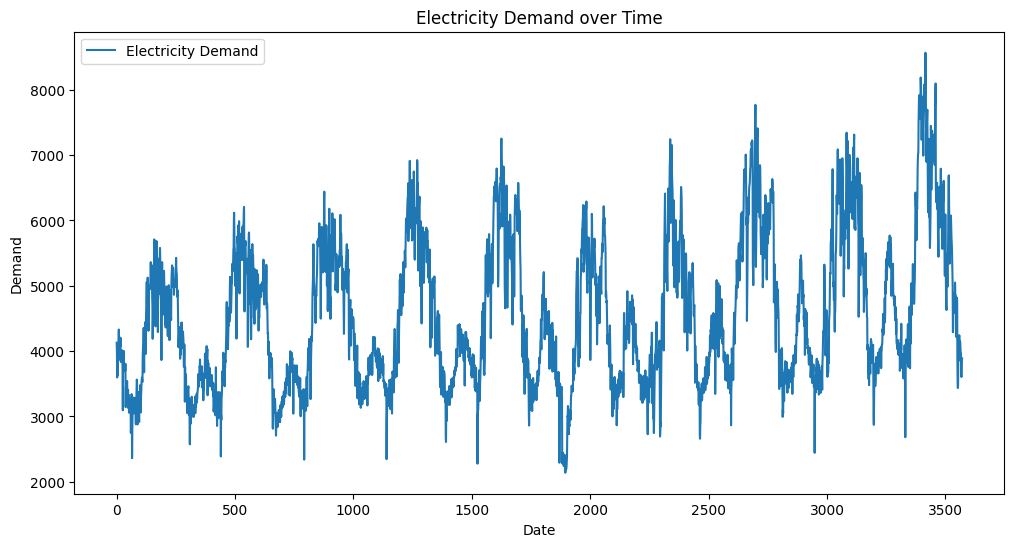

In [61]:
plt.figure(figsize=(12,6))
plt.plot(df['Daily Demand Met (in MW)'], label='Electricity Demand')
plt.title('Electricity Demand over Time')
plt.xlabel('Date')
plt.ylabel('Demand')
plt.legend()
plt.show()


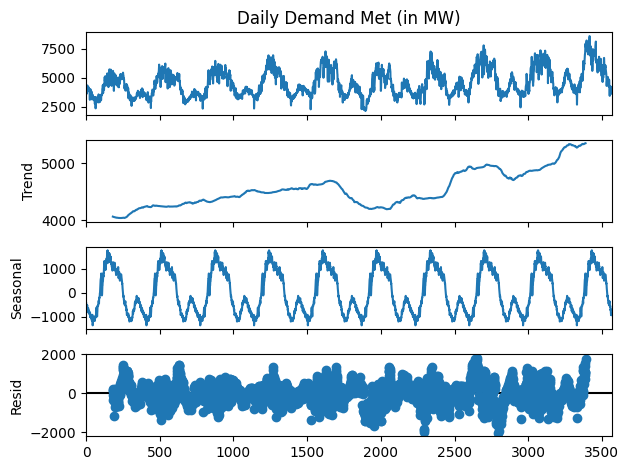

In [62]:
# Decompose the time series
from statsmodels.tsa.seasonal import seasonal_decompose
decomposition = seasonal_decompose(df['Daily Demand Met (in MW)'], model='additive', period=365)
decomposition.plot()
plt.show()

In [63]:
# Perform stationarity test (ADF test)
from statsmodels.tsa.stattools import adfuller
result = adfuller(df['Daily Demand Met (in MW)'])
if result[1] <= 0.05 :
    print(f'ADF Statistic: {result[0]}')
    print(f'p-value: {result[1]}')
else:
    print('Grester than 0.05')

ADF Statistic: -5.224613560956087
p-value: 7.829791703190603e-06


In [64]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3572 entries, 0 to 3571
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Date                      3572 non-null   datetime64[ns]
 1   Weekday                   3572 non-null   int32         
 2   Temperature               3572 non-null   float64       
 3   Humidity                  3572 non-null   float64       
 4   Wind_speed                3572 non-null   float64       
 5   is_Holiday                3572 non-null   int64         
 6   Conditions                3572 non-null   object        
 7   Daily Demand Met (in MW)  3572 non-null   int64         
 8   Season                    3572 non-null   int64         
dtypes: datetime64[ns](1), float64(3), int32(1), int64(3), object(1)
memory usage: 237.3+ KB


# SARIMAX model

In [65]:
df.head()

,Date,Weekday,Temperature,Humidity,Wind_speed,is_Holiday,Conditions,Daily Demand Met (in MW),Season
0,2015-01-01,4,14.2,77.5,10.4,1,fog,4129,1
1,2015-01-02,0,14.4,87.4,11.2,0,rain,4009,1
2,2015-01-03,2,14.6,91.2,9.4,0,rain,3597,1
3,2015-01-04,3,13.6,81.7,16.6,1,fog,3895,1
4,2015-01-05,1,13.2,73.4,25.9,0,clear-day,3627,1


In [66]:
import numpy as np
from pmdarima import auto_arima

import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score
from sklearn.preprocessing import MinMaxScaler
# Assuming df is your original DataFrame with the Demand column
# Select relevant features, normalizing only specific columns
exog_vars = df[['Humidity', 'Temperature', 'Wind_speed','Season']]

# Initialize the StandardScaler
scaler = MinMaxScaler()

# Normalize only the 'Humidity', 'Temperature', and 'Wind Speed' columns
exog_vars[['Humidity', 'Temperature', 'Wind_speed','Season']] = scaler.fit_transform(exog_vars[['Humidity', 'Temperature', 'Wind_speed','Season']])
'''
model = auto_arima(df['Demand'], seasonal=True, m=12,
                   exogenous=exog_vars,
                   stepwise=True, trace=True)
'''
train_data = df['Daily Demand Met (in MW)'][:-365]   # Exclude last 365 rows for training
test_data = df['Daily Demand Met (in MW)'][-365:]    # Last 365 rows for testing

# Split the exogenous variables as well, if you have them
train_exog = exog_vars[:-365]
test_exog = exog_vars[-365:]


# Fit the SARIMAX model with the updated exogenous variables
model = SARIMAX(df['Daily Demand Met (in MW)'], order=(1, 1, 1), seasonal_order=(1, 1, 1, 12), exog=exog_vars)
model_fit = model.fit()

C:\Users\rupes\AppData\Local\Temp\ipykernel_23264\425938550.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  exog_vars[['Humidity', 'Temperature', 'Wind_speed','Season']] = scaler.fit_transform(exog_vars[['Humidity', 'Temperature', 'Wind_speed','Season']])


In [67]:
len(df)

3572

In [68]:
# Make predictions
df['SARIMAX_Predictions'] = model_fit.predict(start=len(train_data),end=len(train_data) + len(test_data) - 1, exog=test_exog)

# Shift predictions to align with actual values
df['SARIMAX_Predictions'] = df['SARIMAX_Predictions'].shift(-1)

# Drop NaN values after shifting
df = df.dropna()

# Evaluate the model
predictions = df['SARIMAX_Predictions']
actual = df['Daily Demand Met (in MW)']

# Calculate and print evaluation metrics
mae = mean_absolute_error(actual, predictions)
mse = mean_squared_error(actual, predictions)
rmse = np.sqrt(mse)
mape = mean_absolute_percentage_error(actual, predictions)
r2 = r2_score(actual, predictions)

print(f'MAE: {mae}, MSE: {mse}, RMSE: {rmse}, MAPE: {mape * 100:.2f}%, R2: {r2}')

MAE: 63.9012526657289, MSE: 6993.687927149506, RMSE: 83.62827229561488, MAPE: 1.22%, R2: 0.9959087425947681


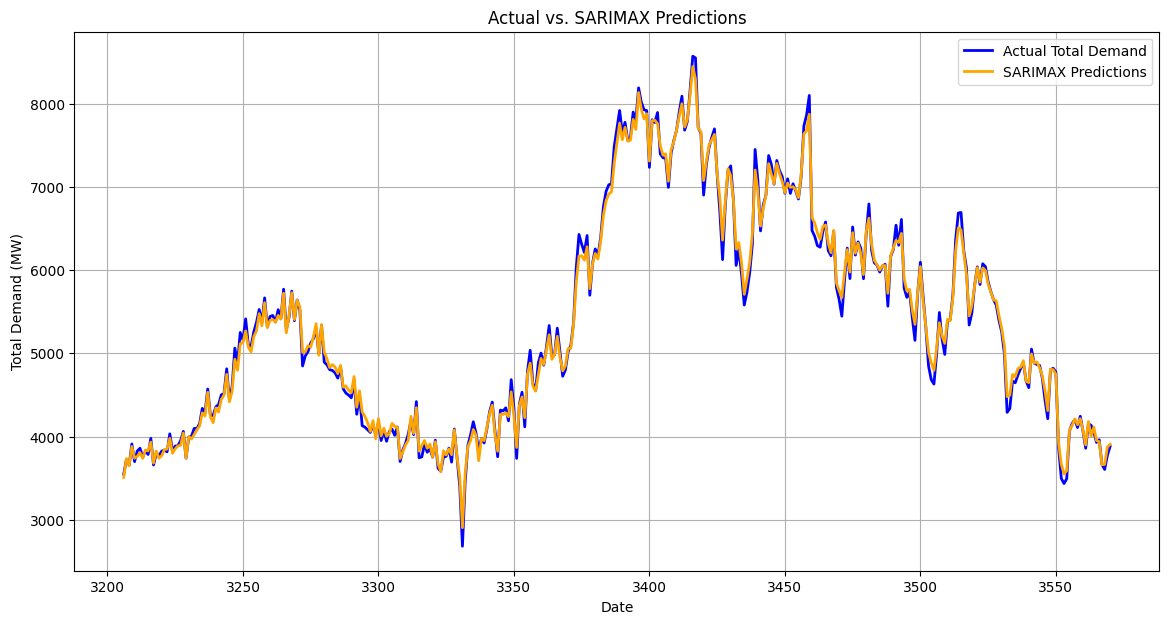

In [69]:
import matplotlib.pyplot as plt

#actual = df['Demand']
#predictions = df['SARIMAX_Predictions']

plt.figure(figsize=(14, 7))
plt.plot(actual.index, actual, label='Actual Total Demand', color='blue', linewidth=2)
plt.plot(predictions.index, predictions, label='SARIMAX Predictions', color='orange', linewidth=2)
plt.title('Actual vs. SARIMAX Predictions')
plt.xlabel('Date')
plt.ylabel('Total Demand (MW)')
plt.legend()
plt.grid()
plt.show()

In [70]:
df["SARIMAX_Predictions"]

3206    3509.615788
3207    3734.324223
3208    3649.120762
3209    3879.549482
3210    3738.599275
           ...     
3566    3937.214854
3567    3659.987486
3568    3664.921306
3569    3872.552921
3570    3906.786538
Name: SARIMAX_Predictions, Length: 365, dtype: float64

In [71]:
print(df)

           Date  Weekday  Temperature  Humidity  Wind_speed  is_Holiday  \
3206 2023-11-21        5         18.8      70.8        13.7           0   
3207 2023-11-22        6         17.8      67.7        11.2           0   
3208 2023-11-23        4         18.6      65.7         9.4           0   
3209 2023-11-24        0         18.3      70.0         7.6           1   
3210 2023-11-25        2         18.1      69.7         8.2           0   
...         ...      ...          ...       ...         ...         ...   
3566 2024-11-15        0         23.0      61.4        14.8           1   
3567 2024-11-16        2         22.3      62.9         9.4           0   
3568 2024-11-17        3         20.3      73.0        16.6           0   
3569 2024-11-18        1         21.1      59.0        11.2           0   
3570 2024-11-19        5         23.3      21.7        10.4           0   

             Conditions  Daily Demand Met (in MW)  Season  SARIMAX_Predictions  
3206          clea

In [72]:
df.head()

,Date,Weekday,Temperature,Humidity,Wind_speed,is_Holiday,Conditions,Daily Demand Met (in MW),Season,SARIMAX_Predictions
3206,2023-11-21,5,18.8,70.8,13.7,0,clear-day,3548,6,3509.615788
3207,2023-11-22,6,17.8,67.7,11.2,0,clear-day,3724,6,3734.324223
3208,2023-11-23,4,18.6,65.7,9.4,0,clear-day,3656,6,3649.120762
3209,2023-11-24,0,18.3,70.0,7.6,1,clear-day,3911,6,3879.549482
3210,2023-11-25,2,18.1,69.7,8.2,0,partly-cloudy-day,3698,6,3738.599275


In [74]:
# Assuming 'actual' and 'predictions' are defined and have the same length as the sliced dates
df.iloc[:, 0] = pd.to_datetime(df.iloc[:, 0], errors='coerce')  # Convert to datetime

results_df = pd.DataFrame({
    'Date': df["Date"],
    'Actual': actual,
    'Predicted': predictions
})

In [75]:
results_df[:365]

,Date,Actual,Predicted
3206,2023-11-21,3548,3509.615788
3207,2023-11-22,3724,3734.324223
3208,2023-11-23,3656,3649.120762
3209,2023-11-24,3911,3879.549482
3210,2023-11-25,3698,3738.599275
...,...,...,...
3566,2024-11-15,3961,3937.214854
3567,2024-11-16,3663,3659.987486
3568,2024-11-17,3604,3664.921306
3569,2024-11-18,3774,3872.552921


In [76]:
df2 = pd.DataFrame(results_df[['Actual','Predicted']])
df2['diff'] = df2['Actual'] - df2['Predicted']
df2

,Actual,Predicted,diff
3206,3548,3509.615788,38.384212
3207,3724,3734.324223,-10.324223
3208,3656,3649.120762,6.879238
3209,3911,3879.549482,31.450518
3210,3698,3738.599275,-40.599275
...,...,...,...
3566,3961,3937.214854,23.785146
3567,3663,3659.987486,3.012514
3568,3604,3664.921306,-60.921306
3569,3774,3872.552921,-98.552921


In [77]:
df2.to_csv("Final Sarimax Output.csv")

In [87]:
import pickle
with open('sarimax_model.pkl', 'wb') as f:
    pickle.dump(model_fit, f)

In [79]:
import joblib
joblib.dump(model, 'sarimax_model.joblib')

['sarimax_model.joblib']

In [89]:
import pandas as pd
import numpy as np
import requests
import pickle
import joblib
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score

# Your API Key
api_key = "DUS2HREYY2L7ZVCLY7SKDXYDZ"

# Base URL for the Visual Crossing Weather API
base_url = "https://weather.visualcrossing.com/VisualCrossingWebServices/rest/services/timeline"


In [90]:
# Function to fetch daily weather data for a given location and date
def fetch_daily_weather_data(location, date):
    params = {
        "unitGroup": "metric",  # For temperature in Celsius
        "key": api_key,
        "contentType": "json"
    }

    url = f"{base_url}/{location}/{date}"
    response = requests.get(url, params=params)

    if response.status_code == 200:
        data = response.json()
        try:
            if "days" in data:
                day_data = data["days"][0]
                
                # Extract relevant features
                temperature = day_data["temp"]
                humidity = day_data["humidity"]
                windspeed = day_data["windspeed"]
                condition = day_data["conditions"]
                
                return np.array([[temperature, humidity, windspeed, condition]])
            else:
                print("Error: 'days' field is missing in the API response.")
                return None
        except KeyError as e:
            print(f"KeyError: {e} - Check if the response structure has changed.")
            return None
    else:
        print(f"Failed to fetch data. HTTP Status code: {response.status_code}")
        return None

In [ ]:
# Function to prepare data for SARIMAX model
def prepare_sarimax_data(df):
    # Ensure the dataset has a 'Date' column; if not, create one
    if 'Date' not in df.columns:
        df['Date'] = pd.to_datetime(df.index)  # Assuming the index is in datetime format
        print("Note: 'Date' column created from index.")

    # Handle missing 'Weekday' column and create it if necessary
    if 'Weekday' not in df.columns:
        df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
        df['Weekday'] = df['Date'].dt.dayofweek  # Monday=0, Sunday=6

    # Handle missing 'Season' column and create it if necessary
    if 'Season' not in df.columns:
        # Default season assignment based on temperature or any other feature (you can modify this logic as needed)
        print("Season column is missing. Adding default seasons based on temperature.")
        
        # Convert 'Temperature' column to numeric (in case it contains strings)
        df['Temperature'] = pd.to_numeric(df['Temperature'], errors='coerce')

        # Assign seasons based on temperature ranges
        df['Season'] = np.where(df['Temperature'] <= 15, 'Light Winter', 
                                np.where(df['Temperature'] <= 30, 'Light Summer', 'Heavy Summer'))
        print("Seasons assigned based on Temperature.")

    # Map Season to numerical values (if you want to keep this as a numerical feature)
    season_mapping = {
        'Light Winter': 0, 'Heavy Winter': 1, 'Light Summer': 2, 'Heavy Summer': 3,
        'Light Rainy': 4, 'Rainy': 5, 'Autumn': 6
    }
    df['Season'] = df['Season'].map(season_mapping).fillna(-1)  # Filling NaN with -1 if any

    # Scale weather-related features
    scaler = MinMaxScaler()
    df[['Humidity', 'Temperature', 'Wind_speed', 'Season']] = scaler.fit_transform(
        df[['Humidity', 'Temperature', 'Wind_speed', 'Season']]
    )
    
    return df

In [ ]:
# Function to prepare data for SARIMAX model
def prepare_sarimax_data(df):
    if 'Date' not in df.columns:
        df['Date'] = pd.to_datetime(df.index)  # Assuming the index is datetime
        print("Note: 'Date' column created from index.")

    if 'Weekday' not in df.columns:
        df['Weekday'] = df['Date'].dt.dayofweek  # Monday=0, Sunday=6

    if 'Season' not in df.columns:
        df['Temperature'] = pd.to_numeric(df['Temperature'], errors='coerce')
        df['Season'] = np.where(df['Temperature'] <= 15, 'Light Winter',
                                np.where(df['Temperature'] <= 30, 'Light Summer', 'Heavy Summer'))

    season_mapping = {'Light Winter': 0, 'Heavy Winter': 1, 'Light Summer': 2, 'Heavy Summer': 3}
    df['Season'] = df['Season'].map(season_mapping).fillna(-1)

    scaler = MinMaxScaler()
    df[['Humidity', 'Temperature', 'Wind_speed', 'Season']] = scaler.fit_transform(
        df[['Humidity', 'Temperature', 'Wind_speed', 'Season']]
    )
    
    return df

# Function to load the saved SARIMAX model
def load_saved_model(model_path):
    with open(model_path, 'rb') as f:
        model = pickle.load(f)
    return model

# Function to predict using the SARIMAX model
def predict_using_loaded_model(df, model_path, exog_vars):
    model_fit = load_saved_model(model_path)
    test_data = df['Daily Demand Met (in MW)'][-365:]
    test_exog = exog_vars[-365:]

    if len(test_exog) != len(test_data):
        raise ValueError("Mismatch between test data and exogenous variables length.")

    try:
        predictions = model_fit.predict(start=test_data.index[0], end=test_data.index[-1], exog=test_exog)
    except Exception as e:
        print(f"Error during prediction: {e}")
        return

    mae = mean_absolute_error(test_data, predictions)
    mse = mean_squared_error(test_data, predictions)
    rmse = np.sqrt(mse)
    mape = mean_absolute_percentage_error(test_data, predictions)
    r2 = r2_score(test_data, predictions)

    print(f"MAE: {mae}, MSE: {mse}, RMSE: {rmse}, MAPE: {mape * 100:.2f}%, R2: {r2}")

    plt.figure(figsize=(12, 7))
    plt.plot(test_data.index, test_data, label='Actual Demand', color='blue', linewidth=2)
    plt.plot(predictions.index, predictions, label='SARIMAX Predictions', color='orange', linewidth=2)
    plt.title('Actual vs. SARIMAX Predictions')
    plt.xlabel('Date')
    plt.ylabel('Total Demand (MW)')
    plt.legend()
    plt.grid()
    plt.show()

# Function to predict future daily demand
def predict_future_demand(location, future_date, model_path):
    weather_array = fetch_daily_weather_data(location, future_date)
    
    if weather_array is not None:
        future_weather_df = pd.DataFrame(weather_array, columns=["Temperature", "Humidity", "Wind_speed", "Conditions"])
        future_weather_df = prepare_sarimax_data(future_weather_df)
        future_exog = future_weather_df[['Temperature', 'Humidity', 'Wind_speed', 'Season']]
        model_fit = load_saved_model(model_path)
        future_prediction = model_fit.predict(start=len(future_weather_df), end=len(future_weather_df), exog=future_exog).values 
        if len(future_prediction) > 0:
            print(f"Predicted Demand for {location} on {future_date}: {future_prediction[0]:.2f} MW")
        else:
            print("Error: No predictions returned from the model.")
        
        plt.figure(figsize=(6, 4))
        plt.bar([future_date], [future_prediction[0]], color='b', label='Predicted Demand (MW)')
        plt.title(f'Predicted Electricity Demand for {location} on {future_date}')
        plt.xlabel('Date')
        plt.ylabel('Predicted Demand (MW)')
        plt.legend()
        plt.show()

MAE: 226.38131082918167, MSE: 86844.13711765273, RMSE: 294.6932933028045, MAPE: 4.36%, R2: 0.949105938625156


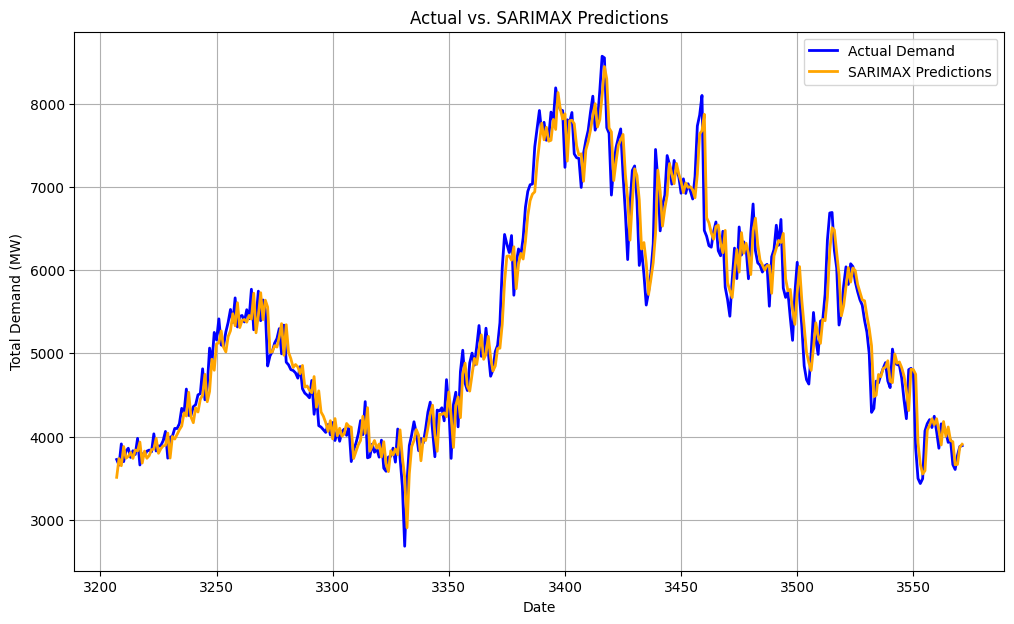

Note: 'Date' column created from index.
Predicted Demand for Delhi on 2025-02-19: 4093.21 MW
Predicted Demand for Delhi on 2025-02-19: 4093.21 MW


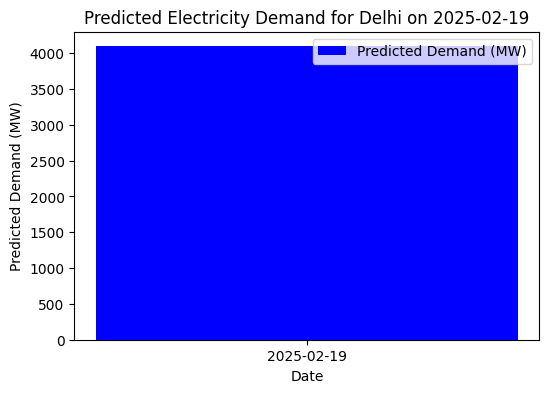

In [96]:
# User input
location = "Delhi"
date = input("Enter the date for future prediction (YYYY-MM-DD): ")
model_path = "R:\Projects\Electricity Demand Prediction\Code\DailyPredictionModel\sarimax_model.pkl"
df = pd.read_excel("R:\Projects\Electricity Demand Prediction\Code\DailyPredictionModel\DD.xlsx")
df = prepare_sarimax_data(df)
exog_vars = df[['Humidity', 'Temperature', 'Wind_speed', 'Season']]

predict_using_loaded_model(df, model_path, exog_vars)
predict_future_demand(location, date, model_path)